# 05 · Nonlinear diffusion

When the diffusivity depends on the solution, the semi-discrete system is nonlinear and the implicit solvers
earn their Newton iterations. Four classic problems show four behaviours: a temperature-dependent conductivity
(a smooth nonlinearity, Newton converges easily), the porous-medium equation (degenerate: the diffusivity
vanishes where u = 0, the solution has a sharp front with compact support, and the right formulation matters),
the Allen-Cahn equation (a bistable reaction whose kink must not move), and the Cahn-Hilliard equation (fourth
order, with conserved mass and a decreasing free energy).

**What you will learn**
- integrate nonlinear diffusion problems with Newton-based implicit methods
- formulate degenerate problems so that Newton converges
- check stationary solutions, conservation and energy decrease
- read the spectrum of bistable and fourth-order problems

**Before you start:** notebooks 03 and 04  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis, stiffness
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Temperature-dependent conductivity

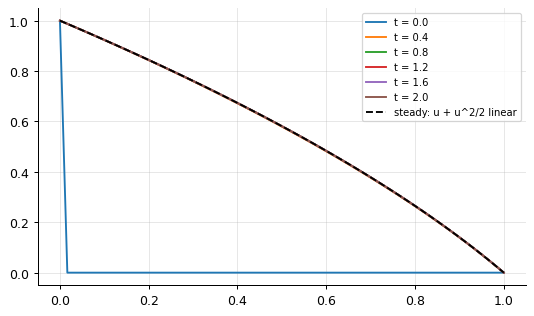

steady-state error 1.4e-05; Newton 2.7 per step, 4 Jacobians over 400 steps


In [2]:
p = pr.nonlinear_conductivity(b=1.0)
s = p.solve("bdf", 0.005, order=2, n_out=5)
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"t = {t:.1f}")
plt.plot(p.x, p.exact(p.x), "k--", label="steady: u + u^2/2 linear"); plt.legend(fontsize=8); plt.show()
print(f"steady-state error {np.max(np.abs(s.y[-1] - p.exact(p.x))):.1e}; Newton {s.newton_iterations / s.steps:.1f} per step, {s.jacobian_evaluations} Jacobians over {s.steps} steps")

With k = 1 + u the steady flux k u_x is constant, so u + u²/2 is linear in x: the solution reproduces it to
10⁻⁵. The Jacobian changes with the solution, and the modified Newton refreshed it four times - during the
early transient when the profile changes fastest - and reused it for the remaining hundreds of steps.

## The porous-medium equation: a degenerate problem

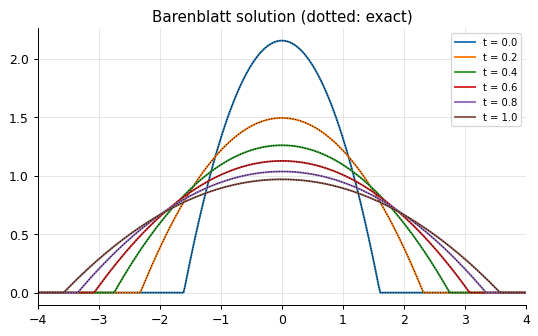

error vs Barenblatt 4.9e-04; mass drift -1.6e-13; front at 3.613 (exact 3.576)
Newton 7.0 per step - the front costs iterations


In [3]:
p = pr.porous_medium(m=2)
s = p.solve("bdf", 2e-3, order=2, n_out=5)
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"t = {t:.1f}"); plt.plot(p.x, p.exact(p.x, t), "k:", lw=0.8)
plt.legend(fontsize=8); plt.title("Barenblatt solution (dotted: exact)"); plt.xlim(-4, 4); plt.show()
print(f"error vs Barenblatt {p.error(s):.1e}; mass drift {p.grid.integrate(s.y[-1]) - p.grid.integrate(p.y0):+.1e}; front at {p.x[s.y[-1] > 1e-6][-1]:.3f} (exact {np.sqrt(12 * 1.1**(2/3)):.3f})")
print(f"Newton {s.newton_iterations / s.steps:.1f} per step - the front costs iterations")

The Barenblatt solution spreads with compact support: the diffusivity m uᵐ⁻¹ is zero ahead of the front, and
the front moves at a finite speed, t^(1/3) for m = 2. Two choices made this work. The equation is discretised
as u_t = (uᵐ)_xx - the linear Laplacian applied to uᵐ - whose Jacobian m uᵐ⁻¹ is continuous, rather than as
∇·(m uᵐ⁻¹ ∇u) with a harmonic mean of diffusivities that is 0/0 at the front; and the domain is wide enough
to contain the support until the end (an earlier version of this problem let the front hit the wall and lost
a quarter of its mass). Even so, Newton needs more iterations than for a smooth problem.

## Allen-Cahn: a stationary kink

In [4]:
p = pr.allen_cahn(eps=0.01)
s = p.solve("bdf", 0.01, order=4, n_out=1)
print(f"after t = {p.t_end}: the kink moved by {np.max(np.abs(s.y[-1] - p.y0)):.1e} (it is an exact stationary solution)")
lam = stiffness.spectrum(p.rhs, p.y0, band=(1, 1)); lam = lam[np.abs(lam) > 1e-9]
print(f"spectrum: from {lam[0].real:.0f} (diffusion) to {lam[-1].real:+.4f}: the slowest mode is the kink's translation, almost neutral")
s_rk = ti.explicit_rk(p.rhs, p.y0, (0, 1.0), 0.95 * stiffness.explicit_step_limit(lam, "rk4"), n_out=1)
print(f"RK4 needs {s_rk.steps} steps for t = 1 where BDF4 took {int(1.0 / 0.01)}")

after t = 5.0: the kink moved by 2.8e-04 (it is an exact stationary solution)
spectrum: from -402 (diffusion) to +0.0005: the slowest mode is the kink's translation, almost neutral
RK4 needs 152 steps for t = 1 where BDF4 took 100


u_t = ε u_xx + u − u³ has two stable states ±1 joined by the kink tanh(x/√(2ε)), a stationary solution: a good
discretisation must not move it, and this one changes it by 3×10⁻⁴ in five time units (the spatial error of
the kink's profile on a grid of 200 points; it does not grow). The spectrum shows the
structure of bistable problems: fast diffusive modes, a reaction time scale of order one, and a nearly neutral
translation mode of the front - the mode that makes fronts drift under numerical perturbations if the scheme
is not careful.

## Cahn-Hilliard: fourth order, conserved mass, decreasing energy

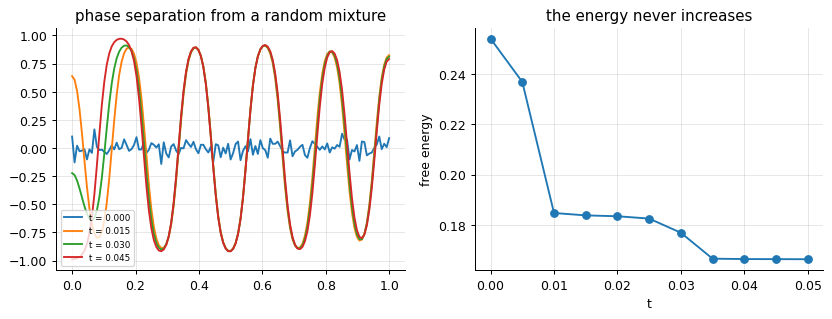

mass drift 1.4e-16; energy monotone: True
extreme eigenvalue -1.81e+06 ~ -eps^2 16/dx^4 = -1.72e+06: an explicit step would be 1.5e-06


In [5]:
p = pr.cahn_hilliard(eps=0.02)
s = p.solve("bdf", 1e-4, order=2, n_out=10)
E = [p.params["energy"](y) for y in s.y]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for t, y in zip(s.t[::3], s.y[::3]):
    axes[0].plot(p.x, y, label=f"t = {t:.3f}")
axes[0].legend(fontsize=7); axes[0].set_title("phase separation from a random mixture")
axes[1].plot(s.t, E, "o-"); axes[1].set_xlabel("t"); axes[1].set_ylabel("free energy"); axes[1].set_title("the energy never increases")
plt.show()
lam = stiffness.spectrum(p.rhs, s.y[-1], band=(2, 2))
print(f"mass drift {np.ptp(analysis.conservation(p.grid, s.y)):.1e}; energy monotone: {bool(np.all(np.diff(E) <= 1e-9))}")
print(f"extreme eigenvalue {lam[0].real:.3g} ~ -eps^2 16/dx^4 = {-0.02**2 * 16 / p.grid.dx**4:.3g}: an explicit step would be {2.8 / abs(lam[0].real):.1e}")

The Cahn-Hilliard equation is the gradient flow of a free energy under the constraint of conserved mass; a
random mixture separates into domains of the two phases that then coarsen. The discretisation conserves mass
to rounding (no-flux ends on a conservative operator) and the energy decreases at every step. The fourth-order
operator makes the system extremely stiff - eigenvalues of order ε²·16/Δx⁴ ≈ −2×10⁶ - so an explicit method
would need steps of 10⁻⁶ where BDF2 takes 10⁻⁴; the Jacobian is pentadiagonal (band 2) and Newton with it is
still cheap.

## Inside the algorithm: the two formulations of the porous-medium operator

In [6]:
g_ = pr.porous_medium().grid
u_ = pr.porous_medium().y0
from engmolines import operators as op, boundary as bc
form_a = op.diffusion(np.maximum(u_, 0) ** 2, g_, 1.0, bc.Dirichlet(0.0), bc.Dirichlet(0.0))              # (u^2)_xx
form_b = op.diffusion(u_, g_, lambda x, u: 2 * np.maximum(u, 0), bc.Dirichlet(0.0), bc.Dirichlet(0.0))    # (2u u_x)_x with harmonic means
print("the two forms agree inside the support to", f"{np.max(np.abs(form_a - form_b)[u_ > 0.1]):.1e}", "and differ at the front, where the harmonic mean of 0 and 2u is 0")

the two forms agree inside the support to 1.2e+00 and differ at the front, where the harmonic mean of 0 and 2u is 0


## Exercises
1. Run the porous-medium problem with m = 3 and m = 4 (the Barenblatt exponents change: alpha = beta = 1/(m+1), kk = (m-1)/(2m(m+1))) and confirm the front speed law t^(1/(m+1)).
2. Perturb the Allen-Cahn kink by adding 0.01 sin(pi x) and integrate to t = 50. Does the kink return to its shape, and does it drift? Measure the drift against eps.
3. **Implement it yourself:** write the Cahn-Hilliard right-hand side as two applications of the 3-point Laplacian with no-flux ghosts, and verify mass conservation and the band (2, 2) of its Jacobian with `linalg.banded_jacobian`.